# Fases 3 y 4: stop words, lematización y stemming

**Responsable:** Fernando · **Módulos:** `src/nlp/stopwords.py`, `src/nlp/lematizacion.py`, `src/nlp/pipeline.py`

Este notebook muestra con ejemplos y con métricas las decisiones de las fases 3 y 4:

1. Qué lista de stop words se usa y por qué se ajustó (con evidencia del dataset).
2. Cómo transforman el texto la lematización y el stemming.
3. El recorrido completo de una consulta por las fases 1 a 4.
4. **Comparación con métricas** (lo que exige el enunciado): lema vs stem y lista ajustada vs lista original de spaCy, con validación cruzada.

> Toda la comparación usa **solo el conjunto de entrenamiento** (validación cruzada estratificada de 5 particiones). El conjunto de prueba no se usa para decidir nada.

In [1]:
import os, sys, json, time
from collections import Counter
from pathlib import Path

# El notebook vive en backend/notebooks/: se trabaja desde backend/ para usar las mismas rutas que train.py
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import f1_score

from src.config import config
from src.data.dataset import cargar_intenciones, dividir
from src.nlp.normalizacion import normalizar
from src.nlp.tokenizacion import tokenizar
from src.nlp.stopwords import lista_stopwords, quitar_stopwords, PALABRAS_CONSERVADAS, STOPWORDS_AGREGADAS
from src.nlp import lematizacion
from src.nlp.lematizacion import lematizar, stemmizar, LEMAS_FIJOS
from src.nlp.pipeline import TextPreprocessor, preprocesar_pasos
from src.nlp.vectorizacion import crear_vectorizador

pd.set_option("display.max_colwidth", 90)
SEED = config["project"]["seed"]

df = cargar_intenciones(config["data"]["raw_path"])
X_train, X_test, y_train, y_test = dividir(df, test_size=config["data"]["test_size"], seed=SEED)
print(f"Dataset: {len(df)} frases, {df['intencion'].nunique()} intenciones")
print(f"Entrenamiento: {len(X_train)} · Prueba: {len(X_test)} (no se usa en este notebook)")

Dataset: 1120 frases, 14 intenciones
Entrenamiento: 896 · Prueba: 224 (no se usa en este notebook)


## 1. Stop words (fase 3)

Se parte de la lista de stop words en español de **spaCy** y se ajusta al dominio. Las palabras se comparan sin tildes, porque la normalización (fase 1, Carmen) ya las quita.

In [2]:
spacy_lista = lista_stopwords("spacy")
ajustada = lista_stopwords("ajustada")
print(f"Lista de spaCy (sin tildes): {len(spacy_lista)} palabras")
print(f"Lista ajustada:              {len(ajustada)} palabras")
print(f"  se quitaron de la lista (se conservan en el texto): {len(spacy_lista - ajustada)}")
print(f"  se agregaron a la lista: {sorted(ajustada - spacy_lista)}")

Lista de spaCy (sin tildes): 462 palabras
Lista ajustada:              434 palabras
  se quitaron de la lista (se conservan en el texto): 35
  se agregaron a la lista: ['disculpa', 'favor', 'oye', 'plis', 'porfa', 'porfis', 'xfa']


### 1.1 Por qué se conservan esas palabras: evidencia del dataset

Para cada palabra que se sacó de la lista, se cuenta en cuántas frases del entrenamiento aparece y **en qué intención aparece más**. Si una palabra se concentra en una intención, es una pista útil para el modelo y borrarla sería perder información.

In [3]:
grupos = {
    "Negación y cantidad": ["no", "sin", "mas", "menos", "poco", "nada", "nunca"],
    "Interrogativas": ["cuanto", "cuanta", "cuantos", "cuantas", "donde", "cuando", "como", "cual", "cuales"],
    "Disponibilidad": ["hay", "tiene", "tienen"],
    "Saludo y despedida": ["buen", "buena", "buenas", "bueno", "buenos", "dias", "hasta", "luego"],
    "Reportes de administración": ["hoy", "ultimo", "ultima", "ultimos", "mayor", "bajo", "total"],
}
tokens_train = [set(tokenizar(normalizar(t))) for t in X_train]
filas = []
for grupo, palabras in grupos.items():
    for palabra in palabras:
        intenciones = Counter(y for toks, y in zip(tokens_train, y_train) if palabra in toks)
        total = sum(intenciones.values())
        if total == 0:
            filas.append((grupo, palabra, 0, "—", "—"))
            continue
        principal, n = intenciones.most_common(1)[0]
        filas.append((grupo, palabra, total, principal, f"{n / total:.0%}"))
evidencia = pd.DataFrame(filas, columns=["grupo", "palabra", "frases", "intención principal", "% en esa intención"])
evidencia

,grupo,palabra,frases,intención principal,% en esa intención
0,Negación y cantidad,no,19,devoluciones,47%
1,Negación y cantidad,sin,12,metodos_pago,33%
2,Negación y cantidad,mas,31,productos_mas_vendidos,81%
3,Negación y cantidad,menos,4,stock_bajo,100%
4,Negación y cantidad,poco,0,—,—
5,Negación y cantidad,nada,0,—,—
6,Negación y cantidad,nunca,0,—,—
7,Interrogativas,cuanto,71,consultar_precio,48%
8,Interrogativas,cuanta,0,—,—
9,Interrogativas,cuantos,2,devoluciones,100%


**Cómo leer la tabla:** por ejemplo, si `cuanto` aparece casi siempre en `consultar_precio` y `bajo` en `stock_bajo`, la lista original de spaCy borraría justamente las palabras que distinguen esas intenciones. Las palabras con 0 frases se conservan por criterio lingüístico (negación, cantidad), aunque este dataset casi no las use.

In [4]:
ejemplos = [
    "¿Cuánto cuesta la chaqueta de cuero, porfa?",
    "¿No tienen jeans en talla 32?",
    "¿Qué productos tienen stock bajo?",
    "Hola, buenas tardes",
    "Dame el total vendido hoy",
    "¿Dónde queda la tienda?",
]
pd.DataFrame([{
    "texto": t,
    "tokens": " ".join(tokenizar(normalizar(t))),
    "lista spaCy": " ".join(quitar_stopwords(tokenizar(normalizar(t)), lista="spacy")),
    "lista ajustada": " ".join(quitar_stopwords(tokenizar(normalizar(t)))),
} for t in ejemplos])

,texto,tokens,lista spaCy,lista ajustada
0,"¿Cuánto cuesta la chaqueta de cuero, porfa?",cuanto cuesta la chaqueta de cuero porfa,cuesta chaqueta cuero porfa,cuanto cuesta chaqueta cuero
1,¿No tienen jeans en talla 32?,no tienen jeans en talla 32,jeans talla 32,no tienen jeans talla 32
2,¿Qué productos tienen stock bajo?,que productos tienen stock bajo,productos stock,productos tienen stock bajo
3,"Hola, buenas tardes",hola buenas tardes,hola tardes,hola buenas tardes
4,Dame el total vendido hoy,dame el total vendido hoy,dame vendido,dame total vendido hoy
5,¿Dónde queda la tienda?,donde queda la tienda,queda tienda,donde queda tienda


Con la lista original, "¿Cuánto cuesta…?" pierde `cuanto`, "stock bajo" pierde `bajo` y "Hola, buenas tardes" pierde `buenas`. La lista ajustada además quita `porfa`, que no aporta a la intención.

### 1.2 Stop words más eliminadas en el dataset

In [5]:
eliminadas = Counter(t for texto in X_train for t in tokenizar(normalizar(texto)) if t in ajustada)
top = pd.DataFrame(eliminadas.most_common(15), columns=["stop word", "veces"])
total_tokens = sum(len(tokenizar(normalizar(t))) for t in X_train)
print(f"Se eliminan {sum(eliminadas.values())} de {total_tokens} tokens ({sum(eliminadas.values()) / total_tokens:.0%})")
top

Se eliminan 3206 de 7545 tokens (42%)


,stop word,veces
0,de,567
1,la,252
2,el,234
3,en,229
4,que,194
5,para,123
6,por,120
7,a,89
8,con,88
9,me,75


## 2. Lematización y stemming (fase 4)

- **Lematización (spaCy `es_core_news_sm`):** usa el contexto de la frase y devuelve palabras reales del diccionario.
- **Stemming (NLTK Snowball, español):** recorta sufijos con reglas fijas; es más rápido, pero produce raíces que no son palabras.

Las tallas (`m`, `xl`, `s/m`) y los números (`32`) pasan sin cambios en ambos.

In [6]:
frase = ["tienen", "jeans", "negros", "cuesta", "abren", "envios", "vendidos", "acabando", "talla", "m", "32"]
pd.DataFrame({"token": frase, "lema (spaCy)": lematizar(frase), "stem (Snowball)": stemmizar(frase)}).T

,0,1,2,3,4,5,6,7,8,9,10
token,tienen,jeans,negros,cuesta,abren,envios,vendidos,acabando,talla,m,32
lema (spaCy),tener,jean,negro,costar,abrir,envio,vendido,acabar,talla,m,32
stem (Snowball),tien,jeans,negr,cuest,abren,envi,vend,acab,tall,m,32


### 2.1 Reducción del vocabulario

Cuantas menos formas distintas tenga el vocabulario, más ejemplos comparte cada término y menos disperso queda TF-IDF. Se cuentan las palabras distintas del entrenamiento después de quitar stop words.

In [7]:
def vocabulario(modo):
    prep = TextPreprocessor(modo=modo).fit([])
    return {t for texto in X_train for t in prep.pasos(texto)["final"]}

sin_reducir = {t for texto in X_train for t in quitar_stopwords(tokenizar(normalizar(texto)))}
v_lema, v_stem = vocabulario("lema"), vocabulario("stem")
pd.DataFrame({
    "representación": ["palabras originales", "lemas", "raíces (stem)"],
    "palabras distintas": [len(sin_reducir), len(v_lema), len(v_stem)],
    "reducción": ["—", f"{1 - len(v_lema) / len(sin_reducir):.0%}", f"{1 - len(v_stem) / len(sin_reducir):.0%}"],
})

,representación,palabras distintas,reducción
0,palabras originales,1297,—
1,lemas,1082,17%
2,raíces (stem),943,27%


### 2.2 Errores de spaCy con texto de chat y su corrección

`es_core_news_sm` se entrenó con noticias y se equivoca con palabras típicas de chat. Se detectaron estos casos y se corrigen con una tabla fija (`LEMAS_FIJOS`). No son reglas de intención: solo evitan que una misma palabra se parta en dos lemas distintos.

In [8]:
from spacy.tokens import Doc
nlp = lematizacion._get_spacy()
casos = [["hola", "buenas", "tardes"], ["muchas", "gracias"], ["gracias", "chau"], ["dame", "el", "reporte"], ["dale", "gracias"], ["adios"]]
filas = []
for tokens in casos:
    crudo = [t.lemma_ for t in nlp(Doc(nlp.vocab, words=tokens))]
    filas.append({"frase": " ".join(tokens), "spaCy sin corregir": " ".join(crudo), "con corrección": " ".join(lematizar(tokens))})
print("Correcciones aplicadas:", LEMAS_FIJOS)
pd.DataFrame(filas)

Correcciones aplicadas: {'hola': 'hola', 'gracias': 'gracias', 'adios': 'adios', 'chau': 'chau', 'dame': 'dar', 'dale': 'dar', 'recomiendas': 'recomendar', 'recomiendame': 'recomendar', 'recomiendeme': 'recomendar', 'recomendarias': 'recomendar', 'recomendaria': 'recomendar', 'sugieres': 'sugerir', 'sugiereme': 'sugerir', 'sugierame': 'sugerir', 'sugeririas': 'sugerir', 'aconsejas': 'aconsejar', 'aconsejame': 'aconsejar'}


,frase,spaCy sin corregir,con corrección
0,hola buenas tardes,holar buena tarde,hola buena tarde
1,muchas gracias,mucho gracia,mucho gracias
2,gracias chau,gracias chau,gracias chau
3,dame el reporte,damar el reporte,dar el reporte
4,dale gracias,dalir gracias,dar gracias
5,adios,adio,adios


"gracias" sale como `gracia` en una frase y como `gracias` en otra: sin la corrección, el modelo vería dos términos distintos para la misma señal de despedida.

## 3. Recorrido completo de una consulta (fases 1 a 4)

`TextPreprocessor` aplica la lematización **antes** de quitar las stop words, para que spaCy vea la frase completa, y después descarta los lemas cuyas palabras originales son stop words. Es el primer paso del modelo guardado en `artifacts/modelo.joblib`, así que el backend usa exactamente este mismo proceso.

In [9]:
pasos = preprocesar_pasos("¿Hay jeans negros en talla 32 o algo más barato, porfa?")
pd.Series({k: (" | ".join(v) if isinstance(v, list) else v) for k, v in pasos.items()}).to_frame("resultado")

,resultado
original,"¿Hay jeans negros en talla 32 o algo más barato, porfa?"
normalizado,hay jeans negros en talla 32 o algo mas barato porfa
tokens,hay | jeans | negros | en | talla | 32 | o | algo | mas | barato | porfa
stopwords_eliminadas,en | o | algo | porfa
sin_stopwords,hay | jeans | negros | talla | 32 | mas | barato
lemas_o_raices,haber | jeans | negro | talla | 32 | mas | barato
modo,lema
final,haber | jeans | negro | talla | 32 | mas | barato


`hay` se conserva (es pista de `consultar_stock`) aunque su lema sea `haber`, que sí es stop word: la decisión de la fase 3 se toma con la palabra que escribió el usuario.

## 4. Comparación con métricas

Se comparan **4 configuraciones** del preprocesamiento (lema o stem × lista ajustada o lista de spaCy) con los **dos modelos** del proyecto. Todo lo demás queda fijo: TF-IDF configurado desde `config.yaml` (fase 5) y los mejores hiperparámetros que encontró `train.py`.

- Validación cruzada estratificada de 5 particiones con semilla fija, solo sobre entrenamiento.
- Métrica principal: **F1 macro** (pesa igual todas las intenciones).

In [10]:
mejores = json.loads(Path(config["artifacts"]["metrics_path"]).read_text(encoding="utf-8"))["modelos"]
C = float(mejores["regresion_logistica"]["mejores_parametros"]["modelo__C"])
cw = mejores["regresion_logistica"]["mejores_parametros"]["modelo__class_weight"]
cw = None if cw in (None, "None") else cw
alpha = float(mejores["naive_bayes"]["mejores_parametros"]["modelo__alpha"])
print(f"Regresión logística: C={C}, class_weight={cw} · Naive Bayes: alpha={alpha}")

modelos = {
    "Regresión logística": lambda: LogisticRegression(C=C, class_weight=cw, max_iter=1000, random_state=SEED),
    "Naive Bayes": lambda: ComplementNB(alpha=alpha),
}
configuraciones = [("lema", "ajustada"), ("stem", "ajustada"), ("lema", "spacy"), ("stem", "spacy")]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def armar(modo, lista, modelo):
    return Pipeline([
        ("preprocesamiento", TextPreprocessor(modo=modo, lista_stopwords=lista)),
        ("vectorizador", crear_vectorizador(config)),
        ("modelo", modelo()),
    ])

filas = []
for nombre, modelo in modelos.items():
    for modo, lista in configuraciones:
        inicio = time.perf_counter()
        cv = cross_validate(armar(modo, lista, modelo), X_train, y_train, cv=skf, scoring=["f1_macro", "accuracy"])
        filas.append({
            "modelo": nombre, "reducción": modo, "stop words": lista,
            "F1 macro CV": cv["test_f1_macro"].mean(), "desv.": cv["test_f1_macro"].std(),
            "exactitud CV": cv["test_accuracy"].mean(), "segundos": time.perf_counter() - inicio,
        })
resultados = pd.DataFrame(filas).sort_values(["modelo", "F1 macro CV"], ascending=[True, False])
resultados.round(4)

Regresión logística: C=10.0, class_weight=balanced · Naive Bayes: alpha=2.0


,modelo,reducción,stop words,F1 macro CV,desv.,exactitud CV,segundos
5,Naive Bayes,stem,ajustada,0.8017,0.0327,0.8036,0.7629
4,Naive Bayes,lema,ajustada,0.8012,0.0232,0.8025,0.2235
6,Naive Bayes,lema,spacy,0.7431,0.0351,0.7455,0.1979
7,Naive Bayes,stem,spacy,0.7345,0.0368,0.7344,0.7457
1,Regresión logística,stem,ajustada,0.8437,0.0209,0.8438,1.6823
0,Regresión logística,lema,ajustada,0.8409,0.0174,0.8415,1.0748
3,Regresión logística,stem,spacy,0.7583,0.0216,0.7556,1.6387
2,Regresión logística,lema,spacy,0.7557,0.0158,0.7567,1.1686


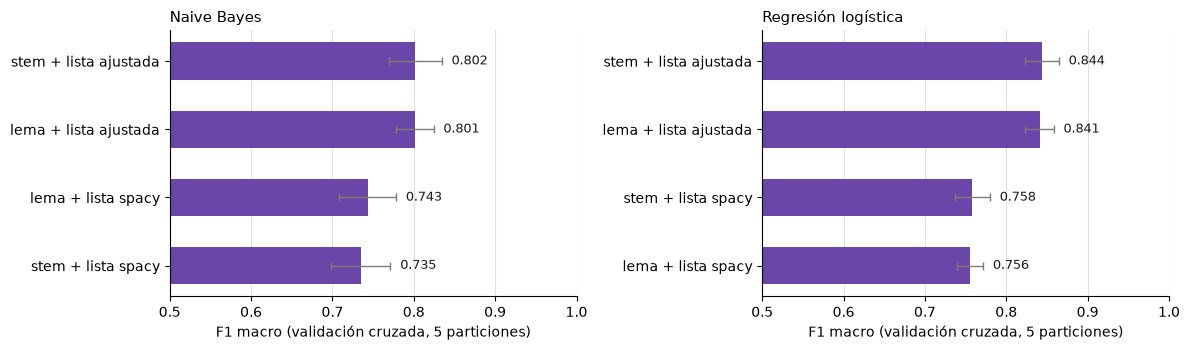

In [11]:
# Una barra por configuración: el largo es el F1 macro y la línea fina es la desviación entre particiones
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for eje, (nombre, grupo) in zip(ejes, resultados.groupby("modelo")):
    grupo = grupo.sort_values("F1 macro CV")
    etiquetas = grupo["reducción"] + " + lista " + grupo["stop words"]
    eje.barh(etiquetas, grupo["F1 macro CV"], xerr=grupo["desv."], color="#6a46a8", height=0.55,
             error_kw={"ecolor": "#827b73", "elinewidth": 1, "capsize": 3})
    for y, (valor, desv) in enumerate(zip(grupo["F1 macro CV"], grupo["desv."])):
        # la etiqueta va después del extremo de la línea de desviación para no taparla
        eje.text(valor + desv + 0.012, y, f"{valor:.3f}", va="center", fontsize=9, color="#1d1b18")
    eje.set_title(nombre, loc="left", fontsize=11)
    eje.set_xlim(0.5, 1.0)
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="x", color="#e5e1da", linewidth=0.8)
    eje.set_axisbelow(True)
ejes[0].set_xlabel("F1 macro (validación cruzada, 5 particiones)")
ejes[1].set_xlabel("F1 macro (validación cruzada, 5 particiones)")
plt.tight_layout()
plt.show()

### 4.1 Dónde cambia el resultado: F1 por intención

Con la regresión logística, se compara la configuración ganadora contra las otras usando las predicciones de validación cruzada (cada frase se predice con un modelo que no la vio).

In [12]:
predicciones = {}
for modo, lista in configuraciones:
    predicciones[(modo, lista)] = cross_val_predict(armar(modo, lista, modelos["Regresión logística"]), X_train, y_train, cv=skf)

clases = sorted(y_train.unique())
por_clase = pd.DataFrame({
    f"{modo} + {lista}": f1_score(y_train, pred, labels=clases, average=None)
    for (modo, lista), pred in predicciones.items()
}, index=clases).round(3)
por_clase["ajustada − spaCy (lema)"] = (por_clase["lema + ajustada"] - por_clase["lema + spacy"]).round(3)
por_clase.sort_values("ajustada − spaCy (lema)", ascending=False)

,lema + ajustada,stem + ajustada,lema + spacy,stem + spacy,ajustada − spaCy (lema)
productos_mas_vendidos,0.803,0.819,0.557,0.571,0.246
consultar_stock,0.752,0.741,0.553,0.576,0.199
consultar_precio,0.871,0.863,0.708,0.685,0.163
horarios_ubicacion,0.860,0.855,0.727,0.742,0.133
stock_bajo,0.790,0.790,0.661,0.655,0.129
saludo,0.977,0.977,0.862,0.894,0.115
reporte_ventas,0.769,0.776,0.701,0.652,0.068
despedida,0.969,0.953,0.911,0.909,0.058
envios,0.859,0.844,0.824,0.848,0.035
ventas_por_categoria,0.768,0.780,0.740,0.714,0.028


### 4.2 Frases que cambian de predicción según la lista de stop words

In [13]:
pa, ps = predicciones[("lema", "ajustada")], predicciones[("lema", "spacy")]
distintas = pd.DataFrame({"texto": X_train.values, "real": y_train.values, "lista ajustada": pa, "lista spaCy": ps})
distintas = distintas[distintas["lista ajustada"] != distintas["lista spaCy"]]
print(f"{len(distintas)} frases cambian de predicción · aciertos ajustada: {(distintas['lista ajustada'] == distintas['real']).sum()} · aciertos spaCy: {(distintas['lista spaCy'] == distintas['real']).sum()}")
distintas.head(12)

142 frases cambian de predicción · aciertos ajustada: 95 · aciertos spaCy: 19


,texto,real,lista ajustada,lista spaCy
15,atienden consultas de forma presencial por las tardes,horarios_ubicacion,horarios_ubicacion,saludo
18,hasta luego estare atento a las novedades,despedida,despedida,horarios_ubicacion
21,cuales faldas de mezclilla tienen menos de cuatro unidades disponibles,stock_bajo,stock_bajo,consultar_stock
27,tienen promociones de meses sin intereses con tarjetas participantes,metodos_pago,metodos_pago,reporte_ventas
31,tienen jeans rectos clasicos para caballero,consultar_stock,consultar_stock,consultar_precio
37,que sacos y blazers tuvieron el mejor volumen comercial en el trimestre,productos_mas_vendidos,consultar_stock,despedida
45,tienen overoles de jean para dama,consultar_stock,consultar_tallas,consultar_precio
54,que prendas basicas representan el mayor porcentaje del volumen de salida,productos_mas_vendidos,productos_mas_vendidos,ventas_por_categoria
58,que corte de pantalon jean prefieren comprar los clientes mom fit o skinny,productos_mas_vendidos,recomendar_productos,consultar_precio
59,cuanto cobran por el abrigo largo con capucha,consultar_precio,consultar_precio,consultar_stock


### 4.3 Frases que cambian de predicción según lema o stem

In [14]:
pl, pst = predicciones[("lema", "ajustada")], predicciones[("stem", "ajustada")]
cambios = pd.DataFrame({"texto": X_train.values, "real": y_train.values, "lema": pl, "stem": pst})
cambios = cambios[cambios["lema"] != cambios["stem"]]
prep_l, prep_s = TextPreprocessor(modo="lema").fit([]), TextPreprocessor(modo="stem").fit([])
cambios["texto con lema"] = [" ".join(prep_l.pasos(t)["final"]) for t in cambios["texto"]]
cambios["texto con stem"] = [" ".join(prep_s.pasos(t)["final"]) for t in cambios["texto"]]
print(f"{len(cambios)} frases cambian · aciertos lema: {(cambios['lema'] == cambios['real']).sum()} · aciertos stem: {(cambios['stem'] == cambios['real']).sum()}")
cambios.head(10)

55 frases cambian · aciertos lema: 20 · aciertos stem: 22


,texto,real,lema,stem,texto con lema,texto con stem
7,si la talla no me queda puedo cambiarla?,devoluciones,consultar_tallas,devoluciones,talla no quedar cambiar,tall no qued cambi
13,cuales son sus productos recomendados?,recomendar_productos,productos_mas_vendidos,recomendar_productos,cual producto recomendado,cual product recomend
22,puedo agendar una visita privada al taller de confeccion,horarios_ubicacion,stock_bajo,consultar_tallas,agendar visita privado taller confeccion,agend visit priv tall confeccion
37,que sacos y blazers tuvieron el mejor volumen comercial en el trimestre,productos_mas_vendidos,consultar_stock,horarios_ubicacion,saco blazer tener volumen comercial trimestre,sac blazers tuv volum comercial trimestr
44,tienen alguna sugerencia de temporada?,recomendar_productos,recomendar_productos,consultar_stock,tener sugerencia temporada,tien sugerent tempor
45,tienen overoles de jean para dama,consultar_stock,consultar_tallas,consultar_stock,tener overol jean dama,tien overol jean dam
58,que corte de pantalon jean prefieren comprar los clientes mom fit o skinny,productos_mas_vendidos,recomendar_productos,consultar_stock,corte pantalon jean preferir comprar cliente mom fit skinny,cort pantalon jean prefier compr client mom fit skinny
87,cuanto se ha vendido en prendas de vestir durante las ultimas 24 horas,reporte_ventas,ventas_por_categoria,consultar_precio,cuanto vender prenda vestir 24 hora,cuant vend prend vest 24 hor
92,cuanto se genero en ventas por prendas de mezclilla y mezclilla elastizada,ventas_por_categoria,ventas_por_categoria,reporte_ventas,cuanto genero venta prenda mezclilla mezclilla elastizado,cuant gener vent prend mezclill mezclill elastiz
96,tienen cobro con tecnologia contactless o sin contacto,metodos_pago,devoluciones,metodos_pago,tener cobro tecnologia contactless sin contacto,tien cobr tecnologi contactless sin contact


## 5. Conclusiones y decisiones

### Stop words: se usa la lista ajustada

| Modelo | Lista ajustada | Lista de spaCy | Diferencia |
|---|---|---|---|
| Regresión logística (lema) | **0,841** | 0,756 | **+8,5 puntos** |
| Naive Bayes (lema) | **0,801** | 0,743 | +5,8 puntos |

- La mejora es grande y aparece con los dos modelos, así que no depende del clasificador.
- Las intenciones que más mejoran son las de las palabras conservadas:
  - `productos_mas_vendidos` (+0,25, por "más" y "mayor")
  - `consultar_stock` (+0,20, por "tienen" y "hay")
  - `consultar_precio` (+0,16, por "cuánto")
  - `horarios_ubicacion`, `stock_bajo` y `saludo` (+0,12 a +0,13, por "dónde", "bajo" y "buenas")
- De las 142 frases de entrenamiento que cambian de predicción entre una lista y otra, la ajustada acierta 95 y la de spaCy 19.
- La lista ajustada elimina el 42 % de los tokens (sobre todo "de", "la", "el", "en"), que no aportan a la intención.

### Lematización o stemming: empate técnico; se mantiene la lematización (`nlp.modo: "lema"`)

| Modelo | Lema | Stem |
|---|---|---|
| Regresión logística | 0,841 (±0,017) | 0,844 (±0,021) |
| Naive Bayes | 0,801 (±0,023) | 0,802 (±0,033) |

- Con las 14 intenciones el stemming queda apenas arriba, pero la diferencia (0,3 puntos) es mucho menor que la variación entre particiones (±2 puntos): con este dataset las dos técnicas rinden igual. Con 13 intenciones ganaba la lematización por un margen igual de chico (0,838 contra 0,833).
- Donde más ayuda el stemming es en `recomendar_productos` (0,855 contra 0,824). El stemming une las formas del verbo ("recomiendas", "recomiendo" → "recomiend") por reglas, mientras que spaCy las lematiza mal sin tildes y hubo que corregirlas a mano ("recomiendas" → "recomiendir").
- El stemming reduce más el vocabulario (27 % contra 17 %), pero produce raíces que no son palabras ("tien", "negr", "cuest").
- **Decisión:** como las métricas empatan, se mantiene la lematización porque sus términos son palabras reales: se muestran en la vista del preprocesamiento del frontend y en los términos más influyentes del modelo, y se pueden explicar. Si se prioriza la métrica, basta con cambiar `nlp.modo` a `"stem"` en `config.yaml` y reentrenar.

### Errores encontrados con este análisis y corregidos

El análisis de las frases que cambian de predicción mostró errores del preprocesamiento:

1. **"buen día necesito ayuda"** se clasificaba como despedida: se conservaba "días" pero no "día", que spaCy considera stop word. Se agregó "dia" a las palabras conservadas.
2. **"están por terminarse esta semana"** generaba un token "el" que el usuario no escribió: spaCy lematiza los verbos con pronombre pegado como "terminar él". Ahora se conserva solo el verbo.
3. **Verbos de recomendación** ("recomiendas", "sugieres", "sugiéreme") que spaCy lematizaba como palabras inexistentes: se agregaron a la tabla de correcciones.

Con las dos primeras correcciones, el F1 macro de la regresión logística en validación cruzada pasó de 0,830 a 0,838 (con 13 intenciones).

### Errores que siguen y por qué

- Frases que mezclan vocabulario de dos intenciones, por ejemplo "si la talla no me queda, ¿puedo cambiarla?" (devoluciones, pero "talla" empuja hacia consultar_tallas).
- Las intenciones de administración se confunden entre sí (`reporte_ventas`, `ventas_por_categoria`, `stock_bajo`) porque comparten "ventas", "vendido" y nombres de prendas.

### Modificación en vivo

Para comparar en la defensa, basta con cambiar una línea de `src/config.yaml` y reentrenar:

```yaml
nlp:
  modo: "stem"               # lema -> stem
  stopwords_extra: ["quiero"]  # agregar una stop word
  stopwords_exclude: ["que"]   # quitar una stop word
```

```bash
python -m src.models.train   # o: docker compose exec backend python -m src.models.train
```